# Descriptive results

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

OUTPUT_FILE = Path("../results/structural_metrics.csv")
STRUCTURAL_METRICS = [
    ("ncloc", "NCLOC"),
    ("functions", "Functions"),
    ("classes", "Classes"),
    ("files", "Files"),
    ("statements", "Statements"),
]


SPARK_CHARS = "▁▂▃▄▅▆▇█"


def unicode_sparkline(values, bins=12):
    counts, _ = np.histogram(values, bins=bins)

    if counts.max() == counts.min():
        return SPARK_CHARS[0] * bins

    scaled = (counts - counts.min()) / (counts.max() - counts.min())

    return "".join(
        SPARK_CHARS[
            int(round(s * (len(SPARK_CHARS) - 1)))
        ]
        for s in scaled
    )


LATEX_DIR = OUTPUT_FILE.parent / "latex"
SPARK_DIR = LATEX_DIR / "sparklines"

SPARK_DIR.mkdir(parents=True, exist_ok=True)


def save_sparkline_png(values, name, bins=20):
    counts, _ = np.histogram(values, bins=bins)

    fig, ax = plt.subplots(figsize=(1.2, 0.28))

    ax.bar(
        range(len(counts)),
        counts,
        width=1.0,
        color="#333333",
    )

    ax.axis("off")

    fig.subplots_adjust(
        left=0,
        right=1,
        top=1,
        bottom=0,
    )

    fig.savefig(
        SPARK_DIR / f"{name}.png",
        dpi=200,
        transparent=True,
    )

    plt.close(fig)


def describe(values):
    return {
        "Min": values.min(),
        "Q1": values.quantile(0.25),
        "Median": values.median(),
        "Mean": values.mean(),
        "Q3": values.quantile(0.75),
        "Max": values.max(),
        "SD": values.std(),
    }


# Read the structural metrics CSV
structural_df = pd.read_csv(OUTPUT_FILE)

rows = []

for col, label in STRUCTURAL_METRICS:

    values = pd.to_numeric(
        structural_df[col],
        errors="coerce",
    ).dropna()

    stats = describe(values)

    save_sparkline_png(
        values,
        col,
    )

    rows.append({
        "Metric": label,
        "Sparkline": unicode_sparkline(values),
        **{
            k: f"{v:.1f}"
            for k, v in stats.items()
        },
    })


description_table = (
    pd.DataFrame(rows)
    .set_index("Metric")[
        [
            "Sparkline",
            "Min",
            "Q1",
            "Median",
            "Mean",
            "Q3",
            "Max",
            "SD",
        ]
    ]
)

latex_file = LATEX_DIR / "structural_metrics_description.tex"

latex_rows = []

for col, label in STRUCTURAL_METRICS:

    values = pd.to_numeric(
        structural_df[col],
        errors="coerce",
    ).dropna()

    stats = describe(values)

    save_sparkline_png(
        values,
        col,
    )

    formatted_stats = {
        k: f"{v:.1f}"
        for k, v in stats.items()
    }

    latex_rows.append(
        f"{label} & "
        f"\\includegraphics[width=1.4cm,height=0.28cm]"
        f"{{fig/sparklines/{col}.png}} & "
        f"{formatted_stats['Min']} & "
        f"{formatted_stats['Q1']} & "
        f"{formatted_stats['Median']} & "
        f"{formatted_stats['Mean']} & "
        f"{formatted_stats['Q3']} & "
        f"{formatted_stats['Max']} & "
        f"{formatted_stats['SD']} \\\\"
    )


latex_file.write_text(
    "\n\n".join(latex_rows),
    encoding="utf-8",
)

print(f"Saved LaTeX rows to {latex_file}")


description_table

Saved LaTeX rows to ..\results\latex\structural_metrics_description.tex


,Sparkline,Min,Q1,Median,Mean,Q3,Max,SD
Metric,,,,,,,,
NCLOC,█▂▂▁▁▁▁▁▁▁▁▁,2592.0,22823.0,61742.5,198195.4,180485.0,2183986.0,362779.7
Functions,█▂▁▁▁▁▁▁▁▁▁▁,135.0,1295.2,3832.5,12368.1,11970.5,148943.0,23779.8
Classes,█▂▁▂▁▁▁▁▁▁▁▁,23.0,195.2,601.5,1795.4,1739.2,25614.0,3787.5
Files,█▂▂▁▁▁▁▁▁▁▁▁,24.0,175.8,517.0,1574.8,1433.8,17054.0,2926.0
Statements,█▃▂▁▁▁▁▁▁▁▁▁,2007.0,10706.2,33002.0,70812.4,83634.0,646401.0,112803.8


# Structural analysis

In [5]:
import json
import csv
from pathlib import Path


INPUT_FILE = Path("../results/analysis_results.jsonl")
OUTPUT_FILE = Path("../results/structural_metrics.csv")


GENERATION_LABELS = {
    0: "no-llm",
    1: "llm-era",
    2: "agentic",
}


SNAPSHOT_YEARS = {
    0: 2021,
    1: 2024,
    2: 2026,
}


STRUCTURAL_METRICS = {
    "ncloc",
    "functions",
    "classes",
    "files",
    "statements",
}


def calculate_cagr(start_value, end_value, years):
    if start_value is None or end_value is None:
        return None

    if start_value <= 0 or years <= 0:
        return None

    return (end_value / start_value) ** (1 / years) - 1


rows = []

with INPUT_FILE.open("r", encoding="utf-8") as file:
    for line in file:
        line = line.strip()

        if not line:
            continue

        project = json.loads(line)

        project_id = project["project_id"]

        sonar_data = (
            project["tools"]
            ["sonarqube"]
            ["data"]
        )

        # Determine the language from SonarQube.
        languages = sonar_data.get("languages", [])

        if "java" in languages:
            language = "java"
        elif "py" in languages:
            language = "python"
        else:
            language = "unknown"

        versions = sonar_data["versions"]

        project_rows = []

        for version_index, (version_id, version_data) in enumerate(versions.items()):
            metrics = version_data["metrics"]

            if version_index not in GENERATION_LABELS:
                raise ValueError(
                    f"Unexpected version index {version_index} "
                    f"for project {project_id}"
                )

            row = {
                "project_id": project_id,
                "language": language,
                "version": version_id,
                "version_order": version_index + 1,
                "generation": GENERATION_LABELS[version_index],
                "year": SNAPSHOT_YEARS[version_index],
            }

            for metric in STRUCTURAL_METRICS:
                row[metric] = metrics.get(metric)

            project_rows.append(row)

        for i in range(1, len(project_rows)):
            previous_row = project_rows[i - 1]
            row = project_rows[i]

            start_year = previous_row["year"]
            end_year = row["year"]
            years = end_year - start_year

            row["cagr_start_year"] = start_year
            row["cagr_end_year"] = end_year
            row["cagr_years"] = years

            for metric in STRUCTURAL_METRICS:
                row[f"cagr_{metric}"] = calculate_cagr(
                    previous_row[metric],
                    row[metric],
                    years,
                )

            rows.append(row)


columns = [
    "project_id",
    "language",
    "version",
    "version_order",
    "generation",
    "year",
    "ncloc",
    "functions",
    "classes",
    "files",
    "statements",
    "cagr_start_year",
    "cagr_end_year",
    "cagr_years",
    "cagr_ncloc",
    "cagr_functions",
    "cagr_classes",
    "cagr_files",
    "cagr_statements",
]


with OUTPUT_FILE.open("w", newline="", encoding="utf-8") as file:
    writer = csv.DictWriter(file, fieldnames=columns)
    writer.writeheader()
    writer.writerows(rows)


print(f"Created {OUTPUT_FILE}")
print(f"Rows: {len(rows)}")
print(f"Java projects: {sum(row['language'] == 'java' for row in rows)}")
print(f"Python projects: {sum(row['language'] == 'python' for row in rows)}")

Created ..\results\structural_metrics.csv
Rows: 100
Java projects: 48
Python projects: 52


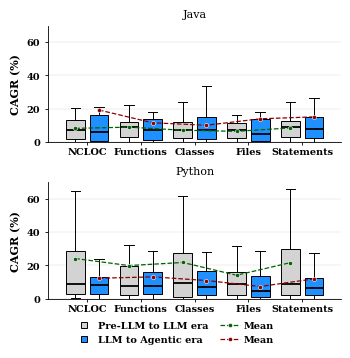

,language,metric,period,N,mean,median,Q1,Q3,min,max
0,Java,NCLOC,Pre-LLM to LLM era,24,8.09%,7.30%,1.83%,13.15%,-36.41%,57.39%
1,Java,Functions,Pre-LLM to LLM era,24,8.82%,8.76%,2.69%,11.77%,-34.32%,59.99%
2,Java,Classes,Pre-LLM to LLM era,24,6.95%,7.19%,2.25%,11.63%,-46.75%,33.89%
3,Java,Files,Pre-LLM to LLM era,24,6.30%,6.86%,1.98%,11.40%,-41.93%,50.83%
4,Java,Statements,Pre-LLM to LLM era,24,8.35%,8.74%,2.97%,12.67%,-32.31%,32.93%
5,Java,NCLOC,LLM to Agentic era,24,19.16%,6.10%,0.74%,15.96%,-47.79%,192.76%
6,Java,Functions,LLM to Agentic era,24,11.45%,6.80%,1.21%,13.69%,-48.02%,102.84%
7,Java,Classes,LLM to Agentic era,24,9.97%,7.32%,1.79%,14.99%,-30.80%,70.02%
8,Java,Files,LLM to Agentic era,24,13.84%,4.42%,0.39%,14.02%,-44.70%,179.22%
9,Java,Statements,LLM to Agentic era,24,15.01%,7.45%,2.20%,15.18%,-19.93%,136.79%



Saved: ..\analysis\structural_plots\structural_cagr_boxplot.pdf


In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

INPUT_FILE = "../results/structural_metrics.csv"
OUTPUT_DIR = Path("../analysis/structural_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5, "pdf.fonttype": 42, "ps.fonttype": 42})

df = pd.read_csv(INPUT_FILE)

metric_columns = {"cagr_ncloc": "NCLOC", "cagr_functions": "Functions", "cagr_classes": "Classes", "cagr_files": "Files", "cagr_statements": "Statements"}
period_order = ["2021-2024", "2024-2026"]
period_labels = {"2021-2024": "Pre-LLM to LLM era", "2024-2026": "LLM to Agentic era"}
period_colors = {"2021-2024": "lightgray", "2024-2026": "dodgerblue"}
mean_colors = {"2021-2024": "darkgreen", "2024-2026": "darkred"}
language_order = ["java", "python"]
language_labels = {"java": "Java", "python": "Python"}

df["period"] = df["cagr_start_year"].astype("Int64").astype(str) + "-" + df["cagr_end_year"].astype("Int64").astype(str)
stats = []

fig, axes = plt.subplots(2, 1, figsize=(3.4, 3.5))
positions = {"2021-2024": [-0.22, 0.78, 1.78, 2.78, 3.78], "2024-2026": [0.22, 1.22, 2.22, 3.22, 4.22]}

for ax, language in zip(axes, language_order):
    language_df = df[df["language"].str.lower() == language]
    for period in period_order:
        xs, means = [], []
        for metric_index, (metric, metric_label) in enumerate(metric_columns.items()):
            values = language_df.loc[language_df["period"] == period, metric].dropna() * 100
            if values.empty:
                continue
            position = positions[period][metric_index]
            ax.boxplot([values], positions=[position], widths=0.35, patch_artist=True, showfliers=False,
                       boxprops=dict(facecolor=period_colors[period], edgecolor="black", linewidth=0.7),
                       whiskerprops=dict(color="black", linewidth=0.7),
                       capprops=dict(color="black", linewidth=0.7),
                       medianprops=dict(color="black", linewidth=1.3))
            xs.append(position)
            means.append(values.mean())
            stats.append({"language": language_labels[language], "metric": metric_label, "period": period_labels[period], "N": len(values), "mean": values.mean(), "median": values.median(), "Q1": values.quantile(0.25), "Q3": values.quantile(0.75), "min": values.min(), "max": values.max()})
        ax.plot(xs, means, color=mean_colors[period], linestyle="--", marker="o", markersize=3, markeredgecolor="white", markeredgewidth=0.4, linewidth=0.9, zorder=5)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set_ylim(0, 70)
    ax.set_ylabel("CAGR (%)")
    ax.set_title(language_labels[language])
    ax.set_xticks(range(len(metric_columns)))
    ax.set_xticklabels(metric_columns.values())
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", pad=1.5)

handles = [plt.Line2D([0], [0], color="black", marker="s", markersize=5, markerfacecolor=period_colors[p], markeredgecolor="black", markeredgewidth=0.7, linestyle="None", label=period_labels[p]) for p in period_order]
handles.extend([plt.Line2D([0], [0], color=mean_colors[p], linestyle="--", marker="o", markersize=3, markeredgecolor="white", markeredgewidth=0.4, linewidth=0.9, label=f"Mean") for p in period_order])

fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=2, frameon=False, columnspacing=1.2, handletextpad=0.4)
fig.subplots_adjust(left=0.13, right=0.99, bottom=0.16, top=0.94, hspace=0.35)

output_file = OUTPUT_DIR / "structural_cagr_boxplot.pdf"
plt.savefig(output_file, format="pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

stats_df = pd.DataFrame(stats)
display(stats_df.style.format({"mean": "{:.2f}%", "median": "{:.2f}%", "Q1": "{:.2f}%", "Q3": "{:.2f}%", "min": "{:.2f}%", "max": "{:.2f}%"}))
print(f"\nSaved: {output_file}")

## Statistical testing

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


INPUT_FILE = "../results/structural_metrics.csv"


metric_columns = {
    "cagr_ncloc": "NCLOC",
    "cagr_functions": "Functions",
    "cagr_classes": "Classes",
    "cagr_files": "Files",
    "cagr_statements": "Statements",
}


def effect_magnitude(r_rb):
    if pd.isna(r_rb):
        return np.nan

    magnitude = abs(r_rb)

    if magnitude < 0.10:
        return "negligible"
    if magnitude < 0.30:
        return "small"
    if magnitude < 0.50:
        return "moderate"

    return "large"


df = pd.read_csv(INPUT_FILE)

df["period"] = (
    df["cagr_start_year"].astype("Int64").astype(str)
    + "-"
    + df["cagr_end_year"].astype("Int64").astype(str)
)


results = []


for metric, metric_label in metric_columns.items():

    wide = (
        df[
            ["project_id", "language", "period", metric]
        ]
        .dropna(subset=[metric])
        .pivot(
            index=["project_id", "language"],
            columns="period",
            values=metric
        )
        .dropna(subset=["2021-2024", "2024-2026"])
    )

    x = wide["2021-2024"].to_numpy()
    y = wide["2024-2026"].to_numpy()

    differences = y - x
    nonzero = differences[differences != 0]

    if len(nonzero) == 0:
        statistic = np.nan
        p_value = 1.0
        rank_biserial = 0.0
        hl_estimate = 0.0

    else:
        test = wilcoxon(
            x,
            y,
            alternative="two-sided",
            zero_method="wilcox",
            method="auto"
        )

        statistic = test.statistic
        p_value = test.pvalue

        # Hodges-Lehmann estimate for paired data
        hl_estimate = np.median(differences)

        # Paired rank-biserial correlation.
        # Positive values indicate higher CAGR in the Agentic era.
        ranks = pd.Series(nonzero).abs().rank(
            method="average"
        ).to_numpy()

        positive_rank_sum = ranks[nonzero > 0].sum()
        negative_rank_sum = ranks[nonzero < 0].sum()

        rank_biserial = (
            positive_rank_sum - negative_rank_sum
        ) / (
            positive_rank_sum + negative_rank_sum
        )

    results.append({
        "metric": metric_label,
        "N": len(wide),
        "median_pre_to_llm": np.median(x),
        "median_llm_to_agentic": np.median(y),
        "median_difference": np.median(y) - np.median(x),
        "HL_difference": hl_estimate,
        "rank_biserial": rank_biserial,
        "effect_magnitude": effect_magnitude(rank_biserial),
        "W": statistic,
        "p_value": p_value,
    })


results_df = pd.DataFrame(results)


# Benjamini-Hochberg correction across the five structural metrics
results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)[1]

results_df["significant"] = results_df["p_adjusted"] < 0.05


results_df = results_df[
    [
        "metric",
        "N",
        "median_pre_to_llm",
        "median_llm_to_agentic",
        "median_difference",
        "HL_difference",
        "rank_biserial",
        "effect_magnitude",
        "W",
        "p_value",
        "p_adjusted",
        "significant",
    ]
]


display(
    results_df.style.format({
        "median_pre_to_llm": "{:.4f}",
        "median_llm_to_agentic": "{:.4f}",
        "median_difference": "{:.4f}",
        "HL_difference": "{:.4f}",
        "rank_biserial": "{:.4f}",
        "W": "{:.2f}",
        "p_value": "{:.4f}",
        "p_adjusted": "{:.4f}",
    })
)

,metric,N,median_pre_to_llm,median_llm_to_agentic,median_difference,HL_difference,rank_biserial,effect_magnitude,W,p_value,p_adjusted,significant
0,NCLOC,50,0.0817,0.0722,-0.0095,-0.0214,-0.1843,small,520.00,0.2612,0.4277,False
1,Functions,50,0.0819,0.0689,-0.0130,-0.0018,-0.0165,negligible,627.00,0.9238,0.9238,False
2,Classes,50,0.0758,0.0711,-0.0047,-0.0144,-0.1559,small,517.00,0.3421,0.4277,False
3,Files,50,0.0698,0.0441,-0.0257,-0.0221,-0.2376,small,486.00,0.1460,0.4277,False
4,Statements,50,0.0882,0.0740,-0.0142,-0.0143,-0.1655,small,532.00,0.3137,0.4277,False


## Commit count

In [6]:
import pandas as pd

from pathlib import Path
PARQUET = Path("../results/passing_origins_sample.parquet") 
df = pd.read_parquet(PARQUET)
print(f"Total passing origins: {len(df)}")
df[["url", "head_swhid", "top_language", "total_commits",  "yearly_head_commits_3m"]].head()

Total passing origins: 50


,url,head_swhid,top_language,total_commits,yearly_head_commits_3m
0,https://github.com/RockyLOMO/rxlib,swh:1:rev:5d9bc8d39c7cf18f4ffd3d31182c646ffeeb...,Java,3921,"[(2021-12-28, 189), (2022-12-23, 194), (2023-1..."
1,https://github.com/cgeo/cgeo,swh:1:rev:8f32a27bc6117ec4e5b0ba70d83bb19984ce...,Java,26137,"[(2021-12-30, 233), (2022-12-24, 280), (2023-1..."
2,https://github.com/fr3ts0n/AndrOBD,swh:1:rev:c945feca32c94b7148cdb791ff67631f52fb...,Java,1916,"[(2021-12-22, 62), (2022-12-25, 80), (2023-12-..."
3,https://github.com/Zettelkasten-Team/Zettelkasten,swh:1:rev:77313b1fe087afcc449db6db85fa8ca925a4...,Java,1312,"[(2021-12-31, 32), (2022-12-30, 14), (2023-11-..."
4,https://github.com/AdamaJava/adamajava,swh:1:rev:d15c117378c79724b28cbc661ccd428cc87c...,Java,6551,"[(2021-12-30, 77), (2022-11-25, 42), (2023-12-..."


In [ ]:
print(df["yearly_head_commits_3m"].iloc[15])

[('2021-12-26', 188), ('2022-12-22', 175), ('2023-12-19', 191), ('2024-12-20', 347), ('2025-12-30', 430), ('2026-06-01', 475)]


### Calculate Daily Comit Rate (DCR)

In [7]:
import pandas as pd
from pathlib import Path

PARQUET = Path("../results/passing_origins_sample.parquet")

df = pd.read_parquet(PARQUET)

def extract_commit_counts(values):
    values = dict(values)
    
    result = {}
    for year in [2021, 2024, 2026]:
        matching = [
            (date, count)
            for date, count in values.items()
            if pd.Timestamp(date).year == year
        ]
        
        if matching:
            # Use the observation closest to the end of the target year
            date, count = max(
                matching,
                key=lambda x: pd.Timestamp(x[0])
            )
            result[year] = count
        else:
            result[year] = pd.NA
    
    return result


commit_data = df["yearly_head_commits_3m"].apply(extract_commit_counts)

for year, era in {
    2021: "pre_llm",
    2024: "llm",
    2026: "agentic",
}.items():
    df[f"commits_3m_{era}"] = commit_data.apply(lambda x: x[year])
    df[f"dcr_{era}"] = df[f"commits_3m_{era}"] / 90

result = df[[
    "url", 
    "top_language",
    "commits_3m_pre_llm",
    "dcr_pre_llm",
    "commits_3m_llm",
    "dcr_llm",
    "commits_3m_agentic",
    "dcr_agentic",
]]

display(result.head())

,url,top_language,commits_3m_pre_llm,dcr_pre_llm,commits_3m_llm,dcr_llm,commits_3m_agentic,dcr_agentic
0,https://github.com/RockyLOMO/rxlib,Java,189,2.100000,38,0.422222,186,2.066667
1,https://github.com/cgeo/cgeo,Java,233,2.588889,137,1.522222,115,1.277778
2,https://github.com/fr3ts0n/AndrOBD,Java,62,0.688889,4,0.044444,62,0.688889
3,https://github.com/Zettelkasten-Team/Zettelkasten,Java,32,0.355556,22,0.244444,44,0.488889
4,https://github.com/AdamaJava/adamajava,Java,77,0.855556,57,0.633333,56,0.622222


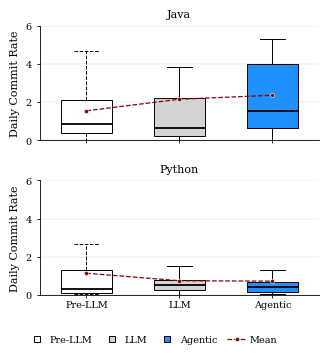

,language,era,N,mean,median,Q1,Q3,min,max
0,Java,Pre-LLM,25,1.5440,0.8556,0.3556,2.0889,0.0111,10.0111
1,Java,LLM,25,2.1498,0.6333,0.2444,2.2000,0.0111,15.9556
2,Java,Agentic,25,2.3551,1.5444,0.6222,4.0111,0.0333,10.0556
3,Python,Pre-LLM,25,1.1444,0.3333,0.1000,1.2889,0.0333,10.0778
4,Python,LLM,25,0.7529,0.5111,0.2444,0.8000,0.0111,3.2333
5,Python,Agentic,25,0.7289,0.4222,0.1889,0.6889,0.0444,4.4667



Saved: ..\analysis\structural_plots\dcr_boxplot.pdf


In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

INPUT_FILE = Path("../results/passing_origins_sample.parquet")
OUTPUT_DIR = Path("../analysis/structural_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5, "pdf.fonttype": 42, "ps.fonttype": 42})

df = pd.read_parquet(INPUT_FILE)

def extract_commit_counts(values):
    values = dict(values)
    result = {}
    for year in [2021, 2024, 2026]:
        matching = [(date, count) for date, count in values.items() if pd.Timestamp(date).year == year]
        result[year] = max(matching, key=lambda x: pd.Timestamp(x[0]))[1] if matching else pd.NA
    return result

commit_data = df["yearly_head_commits_3m"].apply(extract_commit_counts)

for year, era in {2021: "pre_llm", 2024: "llm", 2026: "agentic"}.items():
    df[f"commits_3m_{era}"] = commit_data.apply(lambda x: x[year])
    df[f"dcr_{era}"] = pd.to_numeric(df[f"commits_3m_{era}"], errors="coerce") / 90

era_order = ["dcr_pre_llm", "dcr_llm", "dcr_agentic"]
era_labels = {"dcr_pre_llm": "Pre-LLM", "dcr_llm": "LLM", "dcr_agentic": "Agentic"}
era_colors = {"dcr_pre_llm": "white", "dcr_llm": "lightgray", "dcr_agentic": "dodgerblue"}
language_order = ["Java", "Python"]
positions = {"dcr_pre_llm": 1, "dcr_llm": 2, "dcr_agentic": 3}
stats = []

fig, axes = plt.subplots(2, 1, figsize=(3.4, 3.5), sharex=True, sharey=True)

for ax, language in zip(axes, language_order):
    language_df = df[df["top_language"].str.lower() == language.lower()]
    xs, means = [], []

    for era in era_order:
        values = pd.to_numeric(language_df[era], errors="coerce").dropna()
        if values.empty:
            continue

        position = positions[era]
        ls = "--" if era == "dcr_pre_llm" else "-"

        ax.boxplot([values], positions=[position], widths=0.55, patch_artist=True, showfliers=False,
                   boxprops=dict(facecolor=era_colors[era], edgecolor="black", linestyle=ls, linewidth=0.7),
                   whiskerprops=dict(color="black", linestyle=ls, linewidth=0.7),
                   capprops=dict(color="black", linestyle=ls, linewidth=0.7),
                   medianprops=dict(color="black", linewidth=1.3))

        xs.append(position)
        means.append(values.mean())

        stats.append({"language": language, "era": era_labels[era], "N": len(values), "mean": values.mean(), "median": values.median(), "Q1": values.quantile(0.25), "Q3": values.quantile(0.75), "min": values.min(), "max": values.max()})

    ax.plot(xs, means, color="darkred", linestyle="--", marker="o", markersize=3, markeredgecolor="white", markeredgewidth=0.4, linewidth=0.9, zorder=5)
    ax.set_ylim(0, 6)
    ax.set_ylabel("Daily Commit Rate")
    ax.set_title(language)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels([era_labels[era] for era in era_order])
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", pad=1.5)

handles = [plt.Line2D([0], [0], color="black", marker="s", markersize=5, markerfacecolor=era_colors[era], markeredgecolor="black", markeredgewidth=0.7, linestyle="None", label=era_labels[era]) for era in era_order]
handles.append(plt.Line2D([0], [0], color="darkred", linestyle="--", marker="o", markersize=3, markeredgecolor="white", markeredgewidth=0.4, linewidth=0.9, label="Mean"))

fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.005), ncol=4, frameon=False, columnspacing=1.0, handletextpad=0.3)
fig.subplots_adjust(left=0.17, right=0.99, bottom=0.17, top=0.94, hspace=0.35)

output_file = OUTPUT_DIR / "dcr_boxplot.pdf"
plt.savefig(output_file, format="pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

stats_df = pd.DataFrame(stats)
display(stats_df.style.format({"mean": "{:.4f}", "median": "{:.4f}", "Q1": "{:.4f}", "Q3": "{:.4f}", "min": "{:.4f}", "max": "{:.4f}"}))
print(f"\nSaved: {output_file}")

### Statistical testing

In [14]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests

results = []

for language in ["Java", "Python"]:
    data = df.loc[
        df["top_language"] == language,
        ["dcr_llm", "dcr_agentic"]
    ].apply(pd.to_numeric, errors="coerce").dropna()

    llm = data["dcr_llm"].to_numpy()
    agentic = data["dcr_agentic"].to_numpy()
    differences = agentic - llm
    nonzero = differences != 0
    differences_nz = differences[nonzero]

    if len(differences_nz) > 0:
        statistic, p_value = wilcoxon(
            differences_nz,
            alternative="two-sided",
            zero_method="wilcox"
        )

        ranks = rankdata(np.abs(differences_nz))
        positive_rank_sum = ranks[differences_nz > 0].sum()
        negative_rank_sum = ranks[differences_nz < 0].sum()

        rank_biserial = (
            positive_rank_sum - negative_rank_sum
        ) / (
            positive_rank_sum + negative_rank_sum
        )

        hodges_lehmann = np.median(differences_nz)

    else:
        statistic = np.nan
        p_value = np.nan
        rank_biserial = np.nan
        hodges_lehmann = np.nan

    results.append({
        "language": language,
        "N": len(data),
        "LLM median": np.median(llm),
        "Agentic median": np.median(agentic),
        "HL estimate": hodges_lehmann,
        "rank-biserial": rank_biserial,
        "p-value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p-value (BH)"] = multipletests(
    results_df["p-value"],
    method="fdr_bh"
)[1]

def effect_size(value):
    value = abs(value)
    if value < 0.10:
        return "negligible"
    if value < 0.30:
        return "small"
    if value < 0.50:
        return "moderate"
    return "large"

results_df["effect"] = results_df["rank-biserial"].apply(effect_size)

display(
    results_df.style.format({
        "LLM median": "{:.4f}",
        "Agentic median": "{:.4f}",
        "HL estimate": "{:.4f}",
        "rank-biserial": "{:.4f}",
        "p-value": "{:.4g}",
        "p-value (BH)": "{:.4g}"
    })
)

,language,N,LLM median,Agentic median,HL estimate,rank-biserial,p-value,p-value (BH),effect
0,Java,25,0.6333,1.5444,0.2000,0.4708,0.03934,0.07868,moderate
1,Python,25,0.5111,0.4222,0.0333,-0.0123,0.9571,0.9571,negligible


## Lines modified per commit

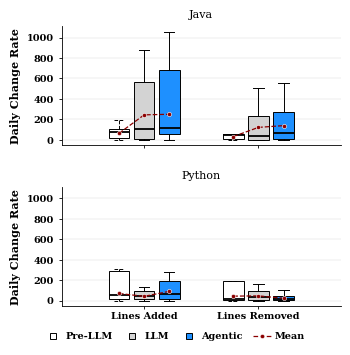

,language,metric,era,N,mean,median,Q1,Q3,min,max
0,Java,Lines Added,Pre-LLM,14,6394.8159,78.6944,13.4472,104.0694,0.1778,88373.1444
1,Java,Lines Added,LLM,16,2159.4840,104.9556,4.4722,563.2361,0.0556,30886.1778
2,Java,Lines Added,Agentic,16,716.5556,118.9111,60.7472,678.4111,0.0333,6029.1222
3,Java,Lines Removed,Pre-LLM,14,2288.6913,43.4056,9.1861,58.9833,0.0778,31387.3333
4,Java,Lines Removed,LLM,16,1339.4597,34.9500,3.3167,230.8278,0.0000,19602.8333
5,Java,Lines Removed,Agentic,16,213.1493,62.8333,11.3889,276.6444,0.0333,1324.8667
6,Python,Lines Added,Pre-LLM,22,568.6217,55.2000,13.2000,289.2139,0.6222,6496.8778
7,Python,Lines Added,LLM,22,141.9768,45.5722,12.1083,95.4056,0.5333,941.2222
8,Python,Lines Added,Agentic,22,141.9131,68.0278,19.7167,188.0750,0.1000,832.0111
9,Python,Lines Removed,Pre-LLM,22,517.2753,19.8000,2.4750,196.2611,0.0333,6601.0333



Saved: ..\analysis\structural_plots\daily_line_activity_boxplot.pdf


In [16]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

INPUT_FILE = Path("../results/git_development_activity_3_months.csv")
OUTPUT_DIR = Path("../analysis/structural_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 2.5, "ytick.major.size": 2.5, "pdf.fonttype": 42, "ps.fonttype": 42})

df = pd.read_csv(INPUT_FILE)
df["project_id"] = df["project_name"].str.extract(r"^(\d+)").astype(int)
df["language"] = df["project_id"].apply(lambda x: "Java" if x < 75 else "Python")
df["snapshot_id"] = df["snapshot_folder"].str.extract(r"^(\d+)").astype(int)
df["era"] = (df["snapshot_id"] % 3).map({0: "Pre-LLM", 1: "LLM", 2: "Agentic"})
df["daily_lines_added"] = pd.to_numeric(df["lines_added"], errors="coerce") / 90
df["daily_lines_removed"] = pd.to_numeric(df["lines_removed"], errors="coerce") / 90

metric_order = ["daily_lines_added", "daily_lines_removed"]
metric_labels = {"daily_lines_added": "Lines Added", "daily_lines_removed": "Lines Removed"}
era_order = ["Pre-LLM", "LLM", "Agentic"]
era_colors = {"Pre-LLM": "white", "LLM": "lightgray", "Agentic": "dodgerblue"}
language_order = ["Java", "Python"]
positions = {"Pre-LLM": [-0.22, 0.78], "LLM": [0, 1], "Agentic": [0.22, 1.22]}
stats = []
plot_data = []

def mean_without_outliers(values):
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    filtered = values[(values >= q1 - 1.5 * iqr) & (values <= q3 + 1.5 * iqr)]
    return filtered.mean()

fig, axes = plt.subplots(2, 1, figsize=(3.4, 3.5), sharex=True, sharey=True)

for ax, language in zip(axes, language_order):
    language_df = df[df["language"] == language]

    for metric_index, metric in enumerate(metric_order):
        xs, means = [], []

        for era in era_order:
            values = pd.to_numeric(language_df.loc[language_df["era"] == era, metric], errors="coerce").dropna()
            if values.empty:
                continue

            position = positions[era][metric_index]
            ls = "--" if era == "Pre-LLM" else "-"

            ax.boxplot([values], positions=[position], widths=0.18, patch_artist=True, showfliers=False,
                       boxprops=dict(facecolor=era_colors[era], edgecolor="black", linestyle=ls, linewidth=0.7),
                       whiskerprops=dict(color="black", linestyle=ls, linewidth=0.7),
                       capprops=dict(color="black", linestyle=ls, linewidth=0.7),
                       medianprops=dict(color="black", linewidth=1.3))

            xs.append(position)
            means.append(mean_without_outliers(values))

            stats.append({"language": language, "metric": metric_labels[metric], "era": era, "N": len(values), "mean": values.mean(), "median": values.median(), "Q1": values.quantile(0.25), "Q3": values.quantile(0.75), "min": values.min(), "max": values.max()})

            plot_rows = language_df.loc[language_df["era"] == era, ["project_name", "snapshot_folder", "snapshot_commit", "snapshot_date", "lines_added", "lines_removed", "daily_lines_added", "daily_lines_removed"]].copy()
            plot_rows["language"] = language
            plot_rows["era"] = era
            plot_data.append(plot_rows)

        mean_color = "darkred"  
        ax.plot(xs, means, color=mean_color, linestyle="--", marker="o", markersize=3, markeredgecolor="white", markeredgewidth=0.4, linewidth=0.9, zorder=5)

    ax.set_ylabel("Daily Change Rate")
    ax.set_title(language)
    ax.set_xticks([0, 1])
    ax.set_xticklabels([metric_labels[m] for m in metric_order])
    ax.grid(axis="y", linewidth=0.3, alpha=0.5)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", pad=1.5)

handles = [plt.Line2D([0], [0], color="black", marker="s", markersize=5, markerfacecolor=era_colors[era], markeredgecolor="black", markeredgewidth=0.7, linestyle="None", label=era) for era in era_order]
handles.append(plt.Line2D([0], [0], color="darkred", linestyle="--", marker="o", markersize=3, markeredgecolor="white", markeredgewidth=0.4, linewidth=0.9, label="Mean"))

fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.015), ncol=4, frameon=False, columnspacing=1.0, handletextpad=0.3)
fig.subplots_adjust(left=0.17, right=0.99, bottom=0.14, top=0.94, hspace=0.35)

output_file = OUTPUT_DIR / "daily_line_activity_boxplot.pdf"
plt.savefig(output_file, format="pdf", bbox_inches="tight")
plt.show()
plt.close(fig)

stats_df = pd.DataFrame(stats)
display(stats_df.style.format({"mean": "{:.4f}", "median": "{:.4f}", "Q1": "{:.4f}", "Q3": "{:.4f}", "min": "{:.4f}", "max": "{:.4f}"}))

plot_data_df = pd.concat(plot_data, ignore_index=True)
print(f"\nSaved: {output_file}")

### Statistical testing

In [33]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests


df["project_key"] = (
    df["project_name"]
    .str.replace(r"^\d+_", "", regex=True)
)


results = []
paired_data = []


comparisons = [
    ("Pre-LLM", "LLM"),
    ("LLM", "Agentic"),
    ("Pre-LLM", "Agentic")
]


for language in ["Java", "Python"]:

    language_df = df[
        df["language"] == language
    ].copy()

    for metric, label in [
        ("daily_lines_added", "Lines Added"),
        ("daily_lines_removed", "Lines Removed")
    ]:

        data = (
            language_df[[
                "project_key",
                "era",
                metric
            ]]
            .pivot_table(
                index="project_key",
                columns="era",
                values=metric,
                aggfunc="first"
            )
        )

        for baseline, comparison in comparisons:

            paired = data.dropna(
                subset=[baseline, comparison]
            )

            baseline_values = paired[baseline].to_numpy()
            comparison_values = paired[comparison].to_numpy()

            differences = (
                comparison_values - baseline_values
            )

            differences_nz = differences[
                differences != 0
            ]

            if len(differences_nz) > 0:

                statistic, p_value = wilcoxon(
                    differences_nz,
                    alternative="two-sided",
                    zero_method="wilcox"
                )

                ranks = rankdata(
                    np.abs(differences_nz)
                )

                positive_rank_sum = ranks[
                    differences_nz > 0
                ].sum()

                negative_rank_sum = ranks[
                    differences_nz < 0
                ].sum()

                rank_biserial = (
                    positive_rank_sum - negative_rank_sum
                ) / (
                    positive_rank_sum + negative_rank_sum
                )

                hodges_lehmann = np.median(
                    differences_nz
                )

            else:

                statistic = np.nan
                p_value = np.nan
                rank_biserial = np.nan
                hodges_lehmann = np.nan

            results.append({
                "language": language,
                "metric": label,
                "comparison": f"{baseline} vs. {comparison}",
                "N": len(paired),
                "Baseline median": (
                    np.median(baseline_values)
                    if len(baseline_values)
                    else np.nan
                ),
                "Comparison median": (
                    np.median(comparison_values)
                    if len(comparison_values)
                    else np.nan
                ),
                "HL estimate": hodges_lehmann,
                "rank-biserial": rank_biserial,
                "p-value": p_value
            })

            paired_rows = paired.reset_index()
            paired_rows["language"] = language
            paired_rows["metric"] = label
            paired_rows["comparison"] = (
                f"{baseline} vs. {comparison}"
            )
            paired_data.append(paired_rows)


results_df = pd.DataFrame(results)


valid_pvalues = results_df["p-value"].notna()

results_df["p-value (BH)"] = np.nan

results_df.loc[
    valid_pvalues,
    "p-value (BH)"
] = multipletests(
    results_df.loc[
        valid_pvalues,
        "p-value"
    ],
    method="fdr_bh"
)[1]


def effect_size(value):

    if pd.isna(value):
        return np.nan

    value = abs(value)

    if value < 0.10:
        return "negligible"

    if value < 0.30:
        return "small"

    if value < 0.50:
        return "moderate"

    return "large"


results_df["effect"] = results_df[
    "rank-biserial"
].apply(effect_size)


display(
    results_df.style.format({
        "Baseline median": "{:.4f}",
        "Comparison median": "{:.4f}",
        "HL estimate": "{:.4f}",
        "rank-biserial": "{:.4f}",
        "p-value": "{:.4g}",
        "p-value (BH)": "{:.4g}"
    })
)


paired_data_df = pd.concat(
    paired_data,
    ignore_index=True
)



,language,metric,comparison,N,Baseline median,Comparison median,HL estimate,rank-biserial,p-value,p-value (BH),effect
0,Java,Lines Added,Pre-LLM vs. LLM,14,78.6944,104.9556,-1.3111,0.0476,0.9032,0.9032,negligible
1,Java,Lines Added,LLM vs. Agentic,16,104.9556,118.9111,53.0278,0.3235,0.2744,0.6652,moderate
2,Java,Lines Added,Pre-LLM vs. Agentic,14,78.6944,118.9111,18.5056,0.3143,0.3258,0.6652,moderate
3,Java,Lines Removed,Pre-LLM vs. LLM,14,43.4056,34.9500,-8.0500,-0.1619,0.6257,0.7509,small
4,Java,Lines Removed,LLM vs. Agentic,16,34.9500,62.8333,9.1278,0.1765,0.5619,0.7492,small
5,Java,Lines Removed,Pre-LLM vs. Agentic,14,43.4056,62.8333,4.9000,0.1048,0.7609,0.83,small
6,Python,Lines Added,Pre-LLM vs. LLM,22,55.2000,45.5722,-19.2444,-0.4308,0.07943,0.6652,moderate
7,Python,Lines Added,LLM vs. Agentic,22,45.5722,68.0278,12.2389,0.2569,0.3053,0.6652,small
8,Python,Lines Added,Pre-LLM vs. Agentic,22,55.2000,68.0278,5.2944,-0.1779,0.4826,0.7239,small
9,Python,Lines Removed,Pre-LLM vs. LLM,22,19.8000,33.9056,-1.3889,-0.2332,0.3535,0.6652,small
